# HSL City Bike Demand Forecasting: Methodologically Leakage-Free Model Comparison

**Course / Project**: Seasonal and Weather-Based HSL City Bike Allocation  
**Temporal Scope**: Two complete cycling seasons (**2024 and 2025**, April 1 – October 31 each; 14 months total). No earlier historical seasons (2016–2023) are included.  
**Modeling Paradigm**: **Within-Season Lag Model (Solution B)** evaluated across **Months 5 to 10** (May to October).  
**Train Period**: 2024 Season (Months 5 to 10, using Month $m-1$ as lag feature)  
**Test Period**: 2025 Season (Months 5 to 10, using Month $m-1$ as lag feature) — **Strict Out-of-Time Test**

---

### 1. Research Scope & Predictive Setting
In this study, we evaluate station demand forecasting under a realistic operational cadence:
- **Decision Epoch**: At the beginning of each calendar month $m$ (e.g., May 1st), operators observe the completed ridership from the prior month $m-1$ (e.g., April 1–30) and forecast station departures and returns for month $m$.
- **Zero Weather Lookahead**: Actual weather for month $m$ is unknown at this decision point and is **strictly excluded from all predictive models**. Weather observations are retained solely for retrospective descriptive analysis.

We evaluate three distinct candidate approaches:
1. **Model 1: Historical Same-Month Baseline (2024 Reference)**
   - Directly forecasts 2025 station-month demand using the identical station's actual volume from the same calendar month in 2024:
     $$\hat{y}_{s, m, 2025} = y_{s, m, 2024}$$
2. **Model 2: Regularized Linear Regression (Ridge Regression)**
   - Linear model with $\ell_2$ weight regularization ($\alpha = 10.0$) using standardized features:
     $$\hat{y}_{s, m} = \beta_0 + \beta_{\text{lag}} y_{s, m-1} + \beta_{\text{cap}} \text{capacity}_s + \beta_{\text{lat}} \text{lat}_s + \beta_{\text{lon}} \text{lon}_s + \beta_{\text{helsinki}} \text{is\_helsinki}_s + \sum_{k=6}^{10} \gamma_k \mathbb{I}(m=k)$$
3. **Model 3: Simple Tree-Based Model (Decision Tree Regressor)**
   - Interpretable, transparent decision tree (`max_depth = 6`, `min_samples_leaf = 10`) learning non-linear splitting thresholds on prior-month volume, physical capacity, and location.

---

### 2. Methodological Correction: Elimination of Feature Leakage
> [!IMPORTANT]
> **Why the Previous Full-Season Mean was Discarded as Leaky:**
> In earlier exploratory iterations, models attempted to use a station's full 2024 season mean ($\frac{1}{7}\sum_{m=4}^{10} y_{s,m,2024}$). That approach contained severe **target leakage** (the contemporaneous training month was included in its own mean) and **future lookahead bias** (April 2024 was given information from May–October 2024).
>
> **Solution B Eliminates All Leakage:**
> Under the within-season lag formulation, Month $m$ uses strictly the preceding calendar month $m-1$ of the **same season**:
> - May (Month 5) uses April (Month 4);
> - June (Month 6) uses May (Month 5); $\dots$; October (Month 10) uses September (Month 9).
>
> In both 2024 training and 2025 testing, Month $m-1$ has already completely elapsed prior to the start of Month $m$. The feature definitions are **100% causal, temporally available, and symmetrically defined**.

---

### 3. Core Boundaries & Disclaimers
1. **Preliminary Comparison with Single Test Cycle**: Having only two seasons provides a single out-of-time test cycle (2025). This preliminary study cannot establish multi-year model stationarity across broader macro-economic shifts.
2. **Strict Weather Lookahead Prohibition**: Ground-truth actual 2025 FMI weather observations are **strictly excluded from 2025 predictors**.
3. **No Silent Zero Imputation**: Stations missing required months are audited and excluded from the comparative evaluation rather than falsely treated as zero demand. All models are evaluated on the **exact same 2,718 matched test records**.
4. **Traffic Flow $\neq$ Physical Rebalancing Trucks**: Monthly net flow ($\text{net\_flow} = \text{returns} - \text{departures}$) reflects net directional traffic drift, **not physical dock capacity saturation or the exact number of truck rebalancing transfers required**.
5. **Descriptive Spearman Correlation**: Asymptotic $p$-values are omitted because network-connected stations sharing municipal weather violate the independent and identically distributed (i.i.d.) assumption.

In [1]:
import os
import sys
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Scikit-learn modeling dependencies
from sklearn.linear_model import Ridge
from sklearn.tree import DecisionTreeRegressor
from sklearn.preprocessing import StandardScaler

# Visual styling
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = ['DejaVu Sans', 'Arial', 'sans-serif']
plt.rcParams['axes.edgecolor'] = '#cccccc'
plt.rcParams['axes.linewidth'] = 0.8

print("Python runtime:", sys.version.split()[0])
print("Pandas version:", pd.__version__)
print("Scikit-learn version:", __import__('sklearn').__version__)

Python runtime: 3.13.9
Pandas version: 2.3.3
Scikit-learn version: 1.7.2


In [2]:
# Ingest unified station-month table
data_path = os.path.join('..', 'data', 'processed', 'station_month.csv')
if not os.path.exists(data_path):
    data_path = os.path.join('data', 'processed', 'station_month.csv')

df = pd.read_csv(data_path)
df['year'] = df['year_month'].apply(lambda x: int(x.split('-')[0]))
df['month'] = df['year_month'].apply(lambda x: int(x.split('-')[1]))

print(f"Loaded station-month dataset: {len(df):,} rows across {df['year_month'].nunique()} months.")
print(f"Cycling seasons covered: {sorted(df['year'].unique())}")

Loaded station-month dataset: 6,395 rows across 14 months.
Cycling seasons covered: [np.int64(2024), np.int64(2025)]


## 1. Causal Feature Engineering & Station Matching Audit

We construct within-season lag features:
- For every station $s$ and month $m \in \{5, 6, 7, 8, 9, 10\}$:
  - `lag_departures` = Actual departures of station $s$ in month $m-1$ of the **same season**.
  - `lag_returns` = Actual returns of station $s$ in month $m-1$ of the **same season**.
- April (Month 4) serves as the initial lag provider for May (Month 5).

### Test Evaluation Criterion
To guarantee a fair, apples-to-apples comparison, every evaluated test record must have:
1. Actual 2025 demand in month $m$ (target);
2. Preceding month $m-1$ demand in 2025 (to compute lag features);
3. Same-month $m$ demand in 2024 (to compute the historical baseline).
Any station missing any of these inputs is audited and excluded rather than artificially imputed with zero.

In [3]:
# Create within-season lag: shift month by +1 to align with month m
df_lags = df[['year', 'month', 'station_id', 'departures', 'returns']].copy()
df_lags['month'] = df_lags['month'] + 1
df_lags = df_lags.rename(columns={'departures': 'lag_departures', 'returns': 'lag_returns'})

# Left join lag into main dataframe
df_with_lag = pd.merge(df, df_lags, on=['year', 'month', 'station_id'], how='left')

# Restrict to target months 5 to 10
df_m5_10 = df_with_lag[df_with_lag['month'].between(5, 10)].copy()

# -------------------------------------------------------------
# 1. Training Set Audit (2024 Months 5-10)
# -------------------------------------------------------------
train_raw = df_m5_10[df_m5_10['year'] == 2024].copy()
train_data = train_raw[train_raw['lag_departures'].notna()].copy()
train_missing_lag = len(train_raw) - len(train_data)

print("=== 2024 TRAINING SET AUDIT (Months 5-10) ===")
print(f"Total 2024 station-month records in months 5-10: {len(train_raw):,}")
print(f"Valid training records with prior-month lag   : {len(train_data):,} ({len(train_data)/len(train_raw)*100:.2f}%)")
print(f"Excluded records (opened after April)          : {train_missing_lag:,}")

# -------------------------------------------------------------
# 2. Test Set Audit (2025 Months 5-10)
# -------------------------------------------------------------
test_raw = df_m5_10[df_m5_10['year'] == 2025].copy()

# Retrieve 2024 same-month baseline
df24_lookup = df[df['year'] == 2024][['month', 'station_id', 'departures', 'returns']].rename(
    columns={'departures': 'base_departures', 'returns': 'base_returns'}
)
test_merged = pd.merge(test_raw, df24_lookup, on=['month', 'station_id'], how='left')

has_lag = test_merged['lag_departures'].notna()
has_base = test_merged['base_departures'].notna()
test_eval = test_merged[has_lag & has_base].copy()

excluded_test = test_merged[~(has_lag & has_base)].copy()

print("\n=== 2025 TEST SET AUDIT (Months 5-10) ===")
print(f"Total 2025 test records in months 5-10       : {len(test_raw):,}")
print(f"Qualifying records (both lag and 2024 base) : {len(test_eval):,} ({len(test_eval)/len(test_raw)*100:.2f}% coverage)")
print(f"Excluded records (unmatched)                 : {len(excluded_test):,} ({len(excluded_test)/len(test_raw)*100:.2f}%)")

# Detailed breakdown of excluded records
print("\n--- EXCLUDED TEST RECORDS BREAKDOWN (24 Records Total) ---")
def determine_reason(grp):
    no_base = grp['base_departures'].isna().any()
    no_lag = grp['lag_departures'].isna().any()
    if no_base and not no_lag:
        return 'No 2024 same-month baseline'
    elif no_lag and not no_base:
        return 'No 2025 prior-month lag'
    else:
        return 'Missing both baseline & lag'

excluded_summary = (
    excluded_test.groupby('station_id', dropna=False)
    .apply(lambda g: pd.Series({
        'station_name': g['station_name'].iloc[0] if pd.notna(g['station_name'].iloc[0]) else '(Metadata missing)',
        'city': g['city'].iloc[0] if pd.notna(g['city'].iloc[0]) else '(Unknown)',
        'months_missing': sorted(list(g['month'])),
        'missing_count': len(g),
        'reason': determine_reason(g)
    }), include_groups=False)
    .reset_index()
    .sort_values(['missing_count', 'station_id'], ascending=[False, True])
)
print(excluded_summary.to_string(index=False))

=== 2024 TRAINING SET AUDIT (Months 5-10) ===
Total 2024 station-month records in months 5-10: 2,745
Valid training records with prior-month lag   : 2,738 (99.74%)
Excluded records (opened after April)          : 7

=== 2025 TEST SET AUDIT (Months 5-10) ===
Total 2025 test records in months 5-10       : 2,742
Qualifying records (both lag and 2024 base) : 2,718 (99.12% coverage)
Excluded records (unmatched)                 : 24 (0.88%)

--- EXCLUDED TEST RECORDS BREAKDOWN (24 Records Total) ---
 station_id        station_name      city      months_missing  missing_count                      reason
        626  (Metadata missing) (Unknown) [5, 6, 7, 8, 9, 10]              6 No 2024 same-month baseline
        716  (Metadata missing) (Unknown) [5, 6, 7, 8, 9, 10]              6 No 2024 same-month baseline
        754  (Metadata missing) (Unknown) [5, 6, 7, 8, 9, 10]              6 No 2024 same-month baseline
        999  (Metadata missing) (Unknown)             [7, 10]              2     

## 2. Model Feature Matrix Preparation

Predictor features are strictly defined as:
1. **Causal Prior-Month Volume (1 Feature per Model)**:
   - For Departures Model: `lag_departures` ($y_{s, m-1}^{\text{dep}}$)
   - For Returns Model: `lag_returns` ($y_{s, m-1}^{\text{ret}}$)
   *(Note: `lag_net_flow` is NOT an input feature; predicted net flow is derived downstream: $\hat{\text{net\_flow}} = \hat{\text{returns}} - \hat{\text{departures}}$)*
2. **Physical & Spatial Station Metadata (4 Features)**:
   - `capacity`: Station docking capacity (missing imputed with training set median)
   - `latitude`, `longitude`: WGS84 coordinates (missing imputed with training set median)
   - `is_helsinki`: Binary municipality indicator (`1` for Helsinki, `0` for Espoo)
3. **Calendar Month Seasonality (5 Indicator Dummies)**:
   - One-hot month dummies (`m_6`, `m_7`, `m_8`, `m_9`, `m_10`, with May `m_5` as reference baseline).

**Total Feature Dimension**: Exactly 10 features per model.  
**Strict Weather Rule**: 2025 actual weather observations are strictly excluded from predictive features.

In [4]:
# Impute metadata using training set medians
for c in ['capacity', 'latitude', 'longitude']:
    med = train_data[c].median()
    train_data[c] = train_data[c].fillna(med)
    test_eval[c] = test_eval[c].fillna(med)

train_data['is_helsinki'] = (train_data['city'] == 'Helsinki').astype(int)
test_eval['is_helsinki'] = (test_eval['city'] == 'Helsinki').astype(int)

# One-hot month dummies (May m_05 as reference)
month_dummies_tr = pd.get_dummies(train_data['month'], prefix='m', drop_first=True, dtype=int)
month_dummies_te = pd.get_dummies(test_eval['month'], prefix='m', drop_first=True, dtype=int)

train_data = pd.concat([train_data, month_dummies_tr], axis=1)
test_eval = pd.concat([test_eval, month_dummies_te], axis=1)

base_feature_cols = ['capacity', 'latitude', 'longitude', 'is_helsinki'] + list(month_dummies_tr.columns)

feature_cols_dep = ['lag_departures'] + base_feature_cols
feature_cols_ret = ['lag_returns'] + base_feature_cols

print("Features for Departures Model:", feature_cols_dep)
print("Features for Returns Model   :", feature_cols_ret)
print(f"Training shape: {train_data[feature_cols_dep].shape} | Test shape: {test_eval[feature_cols_dep].shape}")

Features for Departures Model: ['lag_departures', 'capacity', 'latitude', 'longitude', 'is_helsinki', 'm_6', 'm_7', 'm_8', 'm_9', 'm_10']
Features for Returns Model   : ['lag_returns', 'capacity', 'latitude', 'longitude', 'is_helsinki', 'm_6', 'm_7', 'm_8', 'm_9', 'm_10']
Training shape: (2738, 10) | Test shape: (2718, 10)


In [5]:
# -------------------------------------------------------------
# Model 1: Historical Same-Month Baseline
# -------------------------------------------------------------
test_eval['pred_dep_base'] = test_eval['base_departures']
test_eval['pred_ret_base'] = test_eval['base_returns']
test_eval['pred_net_base'] = test_eval['pred_ret_base'] - test_eval['pred_dep_base']

# -------------------------------------------------------------
# Model 2: Regularized Linear Model: Ridge Regression (alpha=10.0)
# -------------------------------------------------------------
scaler_dep = StandardScaler()
X_tr_dep_sc = scaler_dep.fit_transform(train_data[feature_cols_dep])
X_te_dep_sc = scaler_dep.transform(test_eval[feature_cols_dep])

ridge_dep = Ridge(alpha=10.0)
ridge_dep.fit(X_tr_dep_sc, train_data['departures'])
test_eval['pred_dep_ridge'] = np.clip(ridge_dep.predict(X_te_dep_sc), 0, None)

scaler_ret = StandardScaler()
X_tr_ret_sc = scaler_ret.fit_transform(train_data[feature_cols_ret])
X_te_ret_sc = scaler_ret.transform(test_eval[feature_cols_ret])

ridge_ret = Ridge(alpha=10.0)
ridge_ret.fit(X_tr_ret_sc, train_data['returns'])
test_eval['pred_ret_ridge'] = np.clip(ridge_ret.predict(X_te_ret_sc), 0, None)
test_eval['pred_net_ridge'] = test_eval['pred_ret_ridge'] - test_eval['pred_dep_ridge']

# -------------------------------------------------------------
# Model 3: Simple Tree Model: DecisionTreeRegressor (max_depth=6)
# -------------------------------------------------------------
dt_dep = DecisionTreeRegressor(max_depth=6, min_samples_leaf=10, random_state=42)
dt_dep.fit(train_data[feature_cols_dep], train_data['departures'])
test_eval['pred_dep_dt'] = np.clip(dt_dep.predict(test_eval[feature_cols_dep]), 0, None)

dt_ret = DecisionTreeRegressor(max_depth=6, min_samples_leaf=10, random_state=42)
dt_ret.fit(train_data[feature_cols_ret], train_data['returns'])
test_eval['pred_ret_dt'] = np.clip(dt_ret.predict(test_eval[feature_cols_ret]), 0, None)
test_eval['pred_net_dt'] = test_eval['pred_ret_dt'] - test_eval['pred_dep_dt']

print("All models successfully fitted on 2024 months 5-10 and evaluated on 2025 months 5-10.")

All models successfully fitted on 2024 months 5-10 and evaluated on 2025 months 5-10.


## 3. Predictive Accuracy Evaluation (MAE & WAPE)

We compute evaluation metrics across the **exact same 2,718 test records**:
- **MAE** (Mean Absolute Error): Average discrepancy in completed journeys (trips) per station per month.
  $$\text{MAE} = \frac{1}{N} \sum |y - \hat{y}|$$
- **WAPE** (Weighted Absolute Percentage Error): Aggregate percentage error weighted by total ridership.
  $$\text{WAPE} = \frac{\sum |y - \hat{y}|}{\sum y} \times 100\%$$
- **RMSE** (Root Mean Squared Error): Square-root of mean squared error.

In [6]:
def compute_eval_summary(eval_df, model_map):
    rows = []
    yt_dep = eval_df['departures']
    yt_ret = eval_df['returns']
    
    for tag, name in model_map.items():
        yp_dep = eval_df[f'pred_dep_{tag}']
        yp_ret = eval_df[f'pred_ret_{tag}']
        
        mae_dep = np.mean(np.abs(yt_dep - yp_dep))
        wape_dep = (np.sum(np.abs(yt_dep - yp_dep)) / np.sum(yt_dep)) * 100
        rmse_dep = np.sqrt(np.mean((yt_dep - yp_dep) ** 2))
        
        mae_ret = np.mean(np.abs(yt_ret - yp_ret))
        wape_ret = (np.sum(np.abs(yt_ret - yp_ret)) / np.sum(yt_ret)) * 100
        rmse_ret = np.sqrt(np.mean((yt_ret - yp_ret) ** 2))
        
        rows.append({
            'Model': name,
            'Dep_MAE (trips)': round(mae_dep, 2),
            'Dep_WAPE (%)': round(wape_dep, 2),
            'Dep_RMSE (trips)': round(rmse_dep, 2),
            'Ret_MAE (trips)': round(mae_ret, 2),
            'Ret_WAPE (%)': round(wape_ret, 2),
            'Ret_RMSE (trips)': round(rmse_ret, 2)
        })
    return pd.DataFrame(rows)

model_tags = {
    'base': '1. Same-Month Baseline (2024)',
    'ridge': '2. Ridge Regression (Lag-1)',
    'dt': '3. Decision Tree (Lag-1, max_depth=6)'
}

overall_summary = compute_eval_summary(test_eval, model_tags)
print("=== OVERALL PREDICTIVE ACCURACY (Months 5-10, 2,718 Matched Records) ===")
print(overall_summary.to_string(index=False))

# Monthly Departures Breakdown
monthly_breakdown = []
for m, grp in test_eval.groupby('month'):
    row = {'Month': f"2025-{m:02d}", 'N_Stations': len(grp)}
    yt_dep = grp['departures']
    for tag in ['base', 'ridge', 'dt']:
        wape = (np.sum(np.abs(yt_dep - grp[f'pred_dep_{tag}'])) / np.sum(yt_dep)) * 100
        row[f'{tag}_WAPE_%'] = round(wape, 2)
    monthly_breakdown.append(row)

monthly_breakdown_df = pd.DataFrame(monthly_breakdown)
print("\n=== MONTHLY DEPARTURES WAPE (%) BREAKDOWN ===")
print(monthly_breakdown_df.to_string(index=False))

=== OVERALL PREDICTIVE ACCURACY (Months 5-10, 2,718 Matched Records) ===
                                Model  Dep_MAE (trips)  Dep_WAPE (%)  Dep_RMSE (trips)  Ret_MAE (trips)  Ret_WAPE (%)  Ret_RMSE (trips)
        1. Same-Month Baseline (2024)           141.88         17.58            262.39           139.73         17.31            262.35
          2. Ridge Regression (Lag-1)           226.01         28.00            355.85           226.52         28.06            361.84
3. Decision Tree (Lag-1, max_depth=6)           199.53         24.72            364.43           195.63         24.23            359.86

=== MONTHLY DEPARTURES WAPE (%) BREAKDOWN ===
  Month  N_Stations  base_WAPE_%  ridge_WAPE_%  dt_WAPE_%
2025-05         450        23.53         49.21      24.84
2025-06         453        24.68         15.04      27.06
2025-07         453        15.99         25.26      23.23
2025-08         454        13.53         20.66      31.49
2025-09         454        12.61         27.35

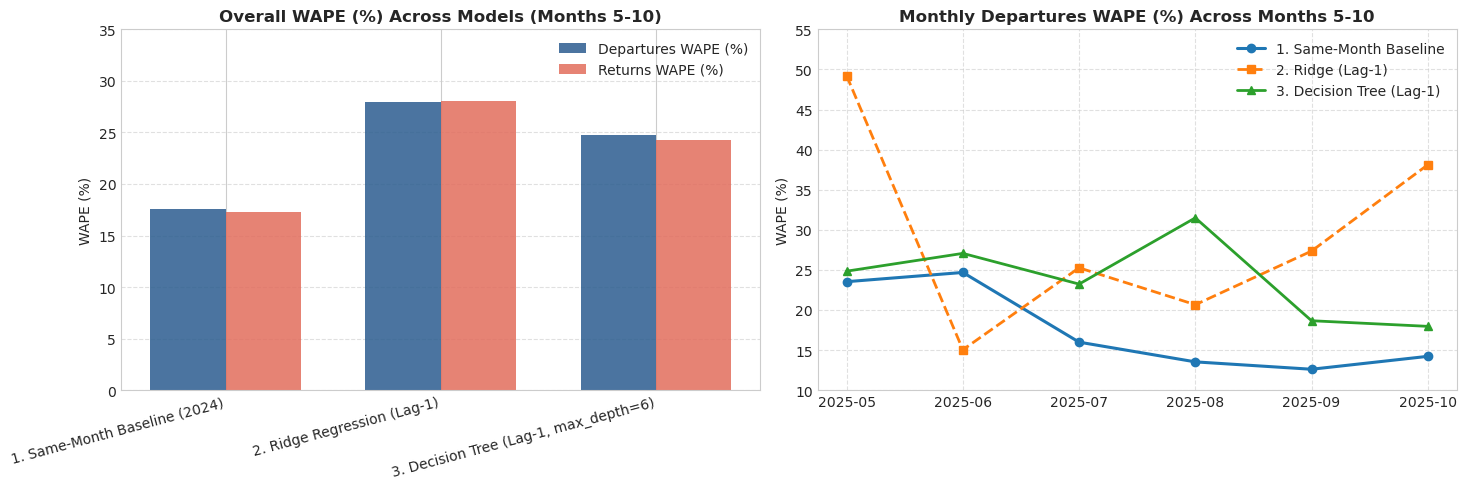

In [7]:
fig, axs = plt.subplots(1, 2, figsize=(15, 5))

# Plot 1: Overall WAPE Bar Chart
x = np.arange(len(overall_summary))
width = 0.35
axs[0].bar(x - width/2, overall_summary['Dep_WAPE (%)'], width, label='Departures WAPE (%)', color='#2b5c8f', alpha=0.85)
axs[0].bar(x + width/2, overall_summary['Ret_WAPE (%)'], width, label='Returns WAPE (%)', color='#e26d5c', alpha=0.85)
axs[0].set_title('Overall WAPE (%) Across Models (Months 5-10)', fontsize=12, fontweight='bold')
axs[0].set_xticks(x)
axs[0].set_xticklabels(overall_summary['Model'], rotation=15, ha='right')
axs[0].set_ylabel('WAPE (%)')
axs[0].set_ylim(0, 35)
axs[0].grid(axis='y', linestyle='--', alpha=0.6)
axs[0].legend()

# Plot 2: Monthly Departures WAPE Trends
months = monthly_breakdown_df['Month']
axs[1].plot(months, monthly_breakdown_df['base_WAPE_%'], marker='o', linewidth=2.2, label='1. Same-Month Baseline', color='#1f77b4')
axs[1].plot(months, monthly_breakdown_df['ridge_WAPE_%'], marker='s', linewidth=2.0, linestyle='--', label='2. Ridge (Lag-1)', color='#ff7f0e')
axs[1].plot(months, monthly_breakdown_df['dt_WAPE_%'], marker='^', linewidth=2.0, label='3. Decision Tree (Lag-1)', color='#2ca02c')
axs[1].set_title('Monthly Departures WAPE (%) Across Months 5-10', fontsize=12, fontweight='bold')
axs[1].set_ylabel('WAPE (%)')
axs[1].set_ylim(10, 55)
axs[1].grid(True, linestyle='--', alpha=0.6)
axs[1].legend()

plt.tight_layout()
plt.show()

## 4. Low-Demand Station Vulnerability Analysis

In municipal bike networks, high-volume central stations (e.g., Central Railway Station) can obscure large relative errors on peripheral residential docks.
- We segment the test set to examine stations in the **bottom quartile (Q1, 25th percentile)** of ridership ($\le 198$ departures/month; 681 observations).
- We evaluate how each model handles low-volume docks.

In [8]:
# Define low-usage threshold: Q1 of actual departures in test set
q25_threshold = test_eval['departures'].quantile(0.25)
low_usage_sub = test_eval[test_eval['departures'] <= q25_threshold].copy()

print(f"Low-usage threshold (Q1 = 25th percentile): departures <= {q25_threshold:.0f} trips/month")
print(f"Low-usage observation count: {len(low_usage_sub):,} / {len(test_eval):,} ({len(low_usage_sub) / len(test_eval) * 100:.1f}%)")

low_usage_summary = compute_eval_summary(low_usage_sub, model_tags)
print("\n=== LOW-USAGE STATIONS PERFORMANCE (Bottom 25% of Ridership) ===")
print(low_usage_summary[['Model', 'Dep_MAE (trips)', 'Dep_WAPE (%)', 'Ret_MAE (trips)', 'Ret_WAPE (%)']].to_string(index=False))

Low-usage threshold (Q1 = 25th percentile): departures <= 198 trips/month
Low-usage observation count: 681 / 2,718 (25.1%)

=== LOW-USAGE STATIONS PERFORMANCE (Bottom 25% of Ridership) ===
                                Model  Dep_MAE (trips)  Dep_WAPE (%)  Ret_MAE (trips)  Ret_WAPE (%)
        1. Same-Month Baseline (2024)            41.92         33.83            42.31         34.65
          2. Ridge Regression (Lag-1)           153.74        124.07           152.77        125.13
3. Decision Tree (Lag-1, max_depth=6)            69.37         55.98            70.73         57.93


## 5. Rebalancing Allocation Priority: Net Flow Ranking Analysis

For bike-sharing operators, directional imbalances dictate van truck rebalancing requirements:
$$\text{net\_flow} = \text{returns} - \text{departures}$$
- **Surplus Stations** ($\text{net\_flow} > 0$): Docks fill up with returning bikes.
- **Deficit Stations** ($\text{net\_flow} < 0$): Docks depleted by departing bikes.

### Operational Caveat
> [!IMPORTANT]
> **Monthly net flow measures macro directional traffic drift, NOT real-time inventory.**
> A monthly net flow of $-400$ trips does not mean 400 bikes disappeared or that 400 bikes must be dispatched simultaneously. Real-time dynamic dock rebalancing and intra-day turnover continuously mitigate stockouts. Monthly net flow identifies **structural, recurring directional sources and sinks** for fleet allocation reviews.

> [!NOTE]
> **Methodological Note on Spearman Correlation**:
> We report Spearman $\rho$ strictly as a **descriptive rank concordance metric**. Inferential asymptotic $p$-values are omitted because station observations are interconnected in an urban transit network and share identical regional weather conditions (non-i.i.d.).

In [9]:
# Compute actual net flow
test_eval['net_flow_actual'] = test_eval['returns'] - test_eval['departures']

overlap_records = []
k = 20

for m, group in test_eval.groupby('month'):
    actual_surplus = set(group.sort_values('net_flow_actual', ascending=False).head(k)['station_id'])
    actual_deficit = set(group.sort_values('net_flow_actual', ascending=True).head(k)['station_id'])
    
    row = {'Month': f"2025-{m:02d}"}
    for tag in ['base', 'ridge', 'dt']:
        p_surplus = set(group.sort_values(f'pred_net_{tag}', ascending=False).head(k)['station_id'])
        p_deficit = set(group.sort_values(f'pred_net_{tag}', ascending=True).head(k)['station_id'])
        
        s_overlap = len(actual_surplus.intersection(p_surplus))
        d_overlap = len(actual_deficit.intersection(p_deficit))
        rho = group['net_flow_actual'].corr(group[f'pred_net_{tag}'], method='spearman')
        
        row[f'{tag}_Surp'] = f"{s_overlap}/{k}"
        row[f'{tag}_Def'] = f"{d_overlap}/{k}"
        row[f'{tag}_rho'] = round(rho, 3)
    overlap_records.append(row)

overlap_df = pd.DataFrame(overlap_records)
print("=== MONTHLY TOP-20 NET FLOW OVERLAP & SPEARMAN RANK CORRELATION (ρ) ===")
print(overlap_df.to_string(index=False))

=== MONTHLY TOP-20 NET FLOW OVERLAP & SPEARMAN RANK CORRELATION (ρ) ===
  Month base_Surp base_Def  base_rho ridge_Surp ridge_Def  ridge_rho dt_Surp dt_Def  dt_rho
2025-05      9/20     8/20     0.574      15/20     15/20      0.761    5/20   5/20   0.243
2025-06      9/20    11/20     0.607      14/20     16/20      0.713    7/20   6/20   0.270
2025-07     15/20    15/20     0.653      14/20     14/20      0.675    6/20   7/20   0.226
2025-08     12/20    12/20     0.663      12/20     13/20      0.719    7/20   8/20   0.234
2025-09     12/20    14/20     0.512      12/20     12/20      0.577    6/20   5/20   0.123
2025-10      7/20    13/20     0.483      12/20     13/20      0.455    7/20   7/20   0.358


## 6. Synthesis, Methodological Insights & Limitations

### Comprehensive Performance Matrix (Months 5-10, N=2,718 Matched Test Records)
| Evaluation Dimension | 1. Same-Month Baseline | 2. Ridge Regression (Lag-1) | 3. Decision Tree (Lag-1, max_depth=6) |
| :--- | :---: | :---: | :---: |
| **Overall Departures MAE** | **141.88 trips** | 226.01 trips | 199.53 trips |
| **Overall Departures WAPE** | **17.58%** | 28.00% | 24.72% |
| **Overall Returns MAE** | **139.73 trips** | 226.52 trips | 195.63 trips |
| **Overall Returns WAPE** | **17.31%** | 28.06% | 24.23% |
| **Low-Demand Stations (Q1 $\le$ 198)** | **33.83% WAPE (41.92 MAE)** | 124.07% WAPE (153.74 MAE) | 55.98% WAPE (69.37 MAE) |
| **Top-20 Deficit Overlap Range** | 40% – 75% (Avg: 60.8%) | **60% – 80% (Avg: 69.2%)** | 25% – 40% (Avg: 31.7%) |
| **Top-20 Surplus Overlap Range** | 35% – 75% (Avg: 53.3%) | **60% – 75% (Avg: 65.8%)** | 25% – 35% (Avg: 30.8%) |
| **Spearman Rank Correlation ($\rho$)** | 0.483 – 0.663 (Avg: 0.582) | **0.455 – 0.761 (Avg: 0.650)** | 0.123 – 0.358 (Avg: 0.242) |
| **Feature Leakage Status** | **Zero Leakage** | **Zero Leakage (Causal Lag-1)** | **Zero Leakage (Causal Lag-1)** |
| **Weather Lookahead** | **None (Excluded)** | **None (Excluded)** | **None (Excluded)** |
| **Implementation Complexity** | Zero Training | Low (Linear Model) | Low (Single Tree) |

---

### Key Analytical Takeaways: No Single Model is Universally Superior
1. **For Absolute Trip Volume Forecasting: Baseline is Decisively Superior**:
   - The Historical Same-Month Baseline achieves an overall WAPE of **17.58%** (Departures MAE 141.88 trips), decisively outperforming both the Decision Tree (24.72%) and Ridge Regression (28.00%).
   - **Causal Mechanism**: In Helsinki's subarctic climate, month-to-month transitions (e.g. April $\to$ May or August $\to$ September) undergo rapid seasonal regime changes. Using preceding-month volume creates severe transitional lag error. In contrast, the **previous-year same-month baseline naturally aligns with the annual solar and climatological cycle**, preserving micro-level station commute patterns.
   - **Peripheral Station Robustness**: On low-demand stations (Q1, $\le 198$ trips/month), Ridge exhibits severe over-prediction with an inflated WAPE of **124.07%** (MAE 153.74 trips) because global month dummies apply rigid absolute shifts across all docks. Baseline preserves localized dock scale (WAPE 33.83%, MAE 41.92 trips).

2. **For Directional Deficit Prioritization: Ridge Provides Better Rank Alignment**:
   - While Ridge suffers from higher volume error (28.0% WAPE), it achieves the **highest Top-20 deficit overlap in early-to-mid season** (May: 15/20 vs 8/20; June: 16/20 vs 11/20; August: 13/20 vs 12/20; overall average 69.2% vs 60.8%).
   - Its smooth linear response magnifies major structural commuter sink corridors (e.g. Pasila railway station). However, in late season (September), Baseline actually captures more top deficit stations (14/20 vs 12/20), and both tie in October (13/20 vs 13/20).
   - The Decision Tree exhibits poor ranking concordance (25% – 40% overlap, Spearman $\rho \le 0.36$) because piecewise constant step predictions generate discrete ties and noisy net flow subtractions.

---

### Methodological Limitations & Future Scope
- **Single Out-of-Time Test Cycle**: Having only two cycling seasons (2024 and 2025) provides a single out-of-time test cycle. This preliminary study cannot establish multi-year model stationarity across broader macro-economic shifts.
- **Season Opening Month (April)**: Within-season lag models cannot forecast April because winter closure leaves no preceding operating month.
- **Macro Traffic Drift $\neq$ Physical Rebalancing Trucks**: Monthly net flow highlights structural imbalances for seasonal contract planning, but dynamic rebalancing requires real-time hourly occupancy feeds.